# AstroGuardian Digital Twin - analysis workflow
**All data are SYNTHETIC (fictional astronauts).** Deviations are monitoring indicators, not diagnoses.
Steps: generate -> clean -> features -> baseline (days 1-14 only) -> profile -> deviation -> three demo scenarios
-> presentation charts -> runtime features -> explanation text (v1.1).

In [1]:
import sys, json
sys.path.insert(0, "../src")
import pandas as pd
from astroguardian_digital_twin.data_generator import generate_dataset, inject_faults
from astroguardian_digital_twin.data_cleaning import clean_wearable_data
from astroguardian_digital_twin.feature_engineering import engineer_features
from astroguardian_digital_twin.baseline import build_baselines, load_config
from astroguardian_digital_twin.profiles import run_pipeline, build_profile
from astroguardian_digital_twin.deviation import compute_deviation, compute_deviation_detailed
pd.set_option("display.width", 140); pd.set_option("display.max_columns", 30)

## 1. Generate synthetic data (seed 42)

In [2]:
raw = generate_dataset(seed=42)
print(raw.shape, raw.astronaut_id.nunique(), "astronauts;", raw.groupby("astronaut_id").size().iloc[0], "hourly rows each")
raw.head()

(14400, 14) 10 astronauts; 1440 hourly rows each


,astronaut_id,timestamp,mission_day,hr,hrv,spo2,resp_rate,temp,sleep_hours,sleep_quality,activity,exercise_score,scenario,is_synthetic
0,AST-001,2026-08-25 00:00:00+00:00,1,58.4,64.2,98.6,14.1,36.66,7.12,0.831,0.241,80.6,normal,True
1,AST-001,2026-08-25 01:00:00+00:00,1,59.0,61.7,98.1,14.1,36.61,7.12,0.831,0.247,80.6,normal,True
2,AST-001,2026-08-25 02:00:00+00:00,1,59.7,60.8,97.9,12.8,36.58,7.12,0.831,0.300,80.6,normal,True
3,AST-001,2026-08-25 03:00:00+00:00,1,60.4,60.9,97.9,13.4,36.44,7.12,0.831,0.303,80.6,normal,True
4,AST-001,2026-08-25 04:00:00+00:00,1,61.0,59.4,97.9,13.9,36.37,7.12,0.831,0.160,80.6,normal,True


## 2. Cleaning: inject faults, then show the cleaning report
Rules: causal forward fill (max 3 h) within one astronaut only; no interpolation; duplicates removed; out-of-range -> missing.

In [3]:
bad, injected = inject_faults(raw.head(3000), seed=5)
clean_bad, report = clean_wearable_data(bad)
print("injected:", injected)
print(json.dumps(report.to_dict(), indent=2))

injected: {'missing_cells_injected': 374, 'invalid_hr_injected': 7, 'duplicates_injected': 18}
{
  "rows_in": 3018,
  "rows_out": 2999,
  "invalid_astronaut_id_rows": 0,
  "invalid_timestamp_rows": 0,
  "rows_before_mission_start_dropped": 0,
  "duplicate_rows_removed": 18,
  "missing_values_original": 374,
  "non_numeric_values": 0,
  "out_of_range_values": 7,
  "out_of_range_by_column": {
    "hr": 7
  },
  "imputed_values": 380,
  "unrecoverable_rows_dropped": 1,
  "invalid_records_total": 7,
  "corrected_values": 380
}


## 3. Feature engineering (causal)
Rolling means use only (t-W, t]; stress reference uses calibration data only.

In [4]:
clean, rep = clean_wearable_data(raw, load_config()["cleaning"], mission_start="2026-08-25T00:00:00Z")
feats = engineer_features(clean, calibration_days=14)
feats[feats.astronaut_id=="AST-001"][["timestamp","hr","hr_roll24h_mean","sleep_debt_7d","stress_score"]].iloc[[30, 300, 900]]

,timestamp,hr,hr_roll24h_mean,sleep_debt_7d,stress_score
30,2026-08-26 06:00:00+00:00,60.2,62.183333,2.04,9.169688
300,2026-09-06 12:00:00+00:00,64.8,62.945833,6.83,32.567296
900,2026-10-01 12:00:00+00:00,65.6,62.191667,7.01,40.079806


## 4. Personal baselines (days 1-14 only)

In [5]:
baselines = build_baselines(feats)
pd.DataFrame({a: {k: b["features"][k]["center"] for k in ("hr","hrv","spo2","sleep_hours","activity")}
              for a, b in baselines.items()}).T.round(2)

,hr,hrv,spo2,sleep_hours,activity
AST-001,62.40,61.15,97.50,6.90,0.53
AST-002,65.90,57.45,97.10,7.24,0.49
AST-003,67.70,56.05,97.50,6.82,0.60
AST-004,66.15,48.45,97.00,6.60,0.48
AST-005,59.70,72.40,97.55,6.92,0.51
AST-006,65.65,65.50,97.60,6.62,0.55
AST-007,55.50,48.35,98.20,6.60,0.47
AST-008,55.80,61.20,98.00,6.87,0.47
AST-009,57.25,56.85,96.70,6.52,0.59
AST-010,59.45,66.50,97.50,6.58,0.69


## 5. Profile for Ahmed (agreed `baseline` keys + documented extensions)

In [6]:
res = run_pipeline(seed=42)
p = res.profiles["AST-001"]
print(json.dumps({k: p[k] for k in ("astronaut_id","name","baseline","recovery_score","calibration")}, indent=2))

{
  "astronaut_id": "AST-001",
  "name": "Ahmed",
  "baseline": {
    "hr": [
      56.47,
      68.33
    ],
    "hrv": [
      51.513,
      70.787
    ],
    "spo2": [
      96.61,
      98.39
    ],
    "sleep_hours": 6.905,
    "temp": [
      36.393,
      36.987
    ],
    "activity": 0.527
  },
  "recovery_score": 78,
  "calibration": {
    "calibration_days": 14,
    "start": "2026-08-25T00:00:00Z",
    "end": "2026-09-07T23:00:00Z",
    "n_rows": 336,
    "n_days_present": 14,
    "complete": true,
    "note": "Only mission days 1..calibration_days were used; later data was ignored."
  }
}


## 6. Deviation of a new reading
Positive = above the astronaut's own baseline, negative = below. Temperature has no percent (degC is an interval scale).

In [7]:
reading = {"hr": 72, "sleep_hours": 4.9}
print(compute_deviation(reading, p))
print(json.dumps(compute_deviation_detailed({"hr": 72, "temp": 37.5}, p)["metrics"], indent=2))

{'hr': 15.38, 'sleep_hours': -29.04}
{
  "hr": {
    "value": 72.0,
    "center": 62.4,
    "center_source": "baseline_detail.center",
    "interval": [
      56.47,
      68.33
    ],
    "abs_deviation": 9.6,
    "pct_deviation": 15.38,
    "position": "above_interval",
    "scaled_deviation": 3.2376
  },
  "temp": {
    "value": 37.5,
    "center": 36.69,
    "center_source": "baseline_detail.center",
    "interval": [
      36.393,
      36.987
    ],
    "abs_deviation": 0.81,
    "pct_deviation": null,
    "position": "above_interval",
    "scaled_deviation": 5.4619
  }
}


## 7. The three demo scenarios (daily mean % deviation, days after calibration)

In [8]:
f = res.features
def daily(aid, cols):
    g = f[(f.astronaut_id==aid) & (f.mission_day>14)]
    return g.groupby("mission_day")[cols].mean()
cols = ["hr_pct_dev","sleep_hours_pct_dev","activity_pct_dev","spo2_pct_dev","temp_delta_c"]
print("Ahmed (normal): mean |dev| over days 15-60"); print(daily("AST-001", cols).abs().mean().round(2))
print("Sara (attention): selected days"); print(daily("AST-002", cols).loc[[30, 40, 45, 50, 55, 60]].round(1))
print("Omar (emergency): last days"); print(daily("AST-003", cols).loc[[50, 55, 56, 58, 60]].round(1))

Ahmed (normal): mean |dev| over days 15-60
hr_pct_dev             0.92
sleep_hours_pct_dev    3.82
activity_pct_dev       7.44
spo2_pct_dev           0.17
temp_delta_c           0.05
dtype: float64
Sara (attention): selected days
             hr_pct_dev  sleep_hours_pct_dev  activity_pct_dev  spo2_pct_dev  temp_delta_c
mission_day                                                                               
30                  2.5                  2.9              -3.8          -0.1           0.2
40                  1.4                 -4.7              15.1          -0.7           0.1
45                  5.7                -10.5             -16.8          -0.5          -0.0
50                  4.9                 -7.7             -22.0          -0.4           0.2
55                  5.3                -16.4              -3.0          -0.1           0.1
60                 13.6                -24.7             -47.6          -0.4           0.2
Omar (emergency): last days
             h

## 8. Pattern checks and caveats
The checks verify the direction/size of injected *synthetic* changes - they are not model predictions and do not
establish real-world accuracy. Risk levels belong to AI Member 2.

In [9]:
from astroguardian_digital_twin.demo_scenarios import evaluate_demo_patterns
ev = evaluate_demo_patterns(res)
{k: ev[k] for k in ("distinct_baselines","ahmed_stable","sara_progressive","omar_emergency_pattern")}

{'distinct_baselines': True,
 'ahmed_stable': True,
 'sara_progressive': True,
 'omar_emergency_pattern': True}

## 9. Charts for the presentation
Saved as PNG to `outputs/figures/` (ready for slides). Bands = the astronaut's **personal normal range** (median +/- 2 robust SD of calibration days 1-14, v1.1).

In [10]:
%matplotlib inline
import matplotlib.pyplot as plt
from pathlib import Path
FIG = Path("../outputs/figures"); FIG.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 160, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
COL = {"AST-001": "#2e7d4f", "AST-002": "#b8860b", "AST-003": "#c0392b"}
NAME = {"AST-001": "Ahmed", "AST-002": "Sara", "AST-003": "Omar"}
prof = res.profiles
def band(ax, aid, metric, color):
    d = prof[aid]["baseline_detail"][metric]
    ax.axhspan(d["low"], d["high"], color=color, alpha=0.12, lw=0)
    ax.axhline(d["center"], color=color, lw=0.8, ls=":")
def day_mean(aid, metric):
    g = f[f.astronaut_id == aid]
    return g.groupby("mission_day")[metric].mean()

### Figure 1 - Why a Digital Twin? A fixed population alarm misses Omar; his personal baseline does not

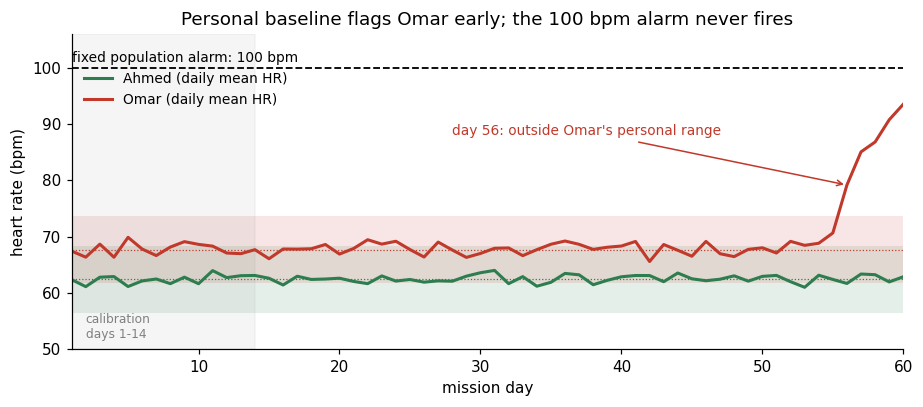

Omar daily-mean HR max: 93.6 bpm  | first day outside personal range: 56


In [11]:
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for aid in ("AST-001", "AST-003"):
    s = day_mean(aid, "hr"); band(ax, aid, "hr", COL[aid])
    ax.plot(s.index, s.values, color=COL[aid], lw=2, label=f"{NAME[aid]} (daily mean HR)")
ax.axhline(100, color="black", lw=1.2, ls="--"); ax.text(1, 101, "fixed population alarm: 100 bpm", fontsize=9)
d = prof["AST-003"]["baseline_detail"]["hr"]; s = day_mean("AST-003", "hr")
first = int(s[(s.index > 14) & (s > d["high"])].index.min())
ax.annotate(f"day {first}: outside Omar's personal range", xy=(first, s[first]), xytext=(28, 88),
            arrowprops=dict(arrowstyle="->", color=COL["AST-003"]), color=COL["AST-003"], fontsize=9)
ax.axvspan(1, 14, color="grey", alpha=0.08); ax.text(2, 52, "calibration\ndays 1-14", fontsize=8, color="grey")
ax.set(xlabel="mission day", ylabel="heart rate (bpm)", ylim=(50, 106), xlim=(1, 60),
       title="Personal baseline flags Omar early; the 100 bpm alarm never fires")
ax.legend(loc="upper left", frameon=False, fontsize=9, bbox_to_anchor=(0, 0.92))
fig.tight_layout(); fig.savefig(FIG / "fig1_why_digital_twin.png"); plt.show()
print("Omar daily-mean HR max:", round(s.max(), 1), "bpm  | first day outside personal range:", first)

### Figure 2 - Sara: gradual sleep loss from day 40 (Attention)

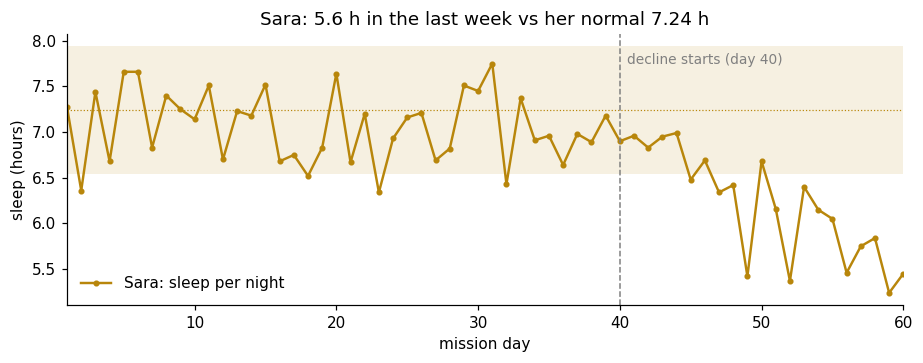

In [12]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
s = day_mean("AST-002", "sleep_hours"); band(ax, "AST-002", "sleep_hours", COL["AST-002"])
ax.plot(s.index, s.values, "o-", ms=3, color=COL["AST-002"], lw=1.6, label="Sara: sleep per night")
ax.axvline(40, color="grey", lw=1, ls="--"); ax.text(40.5, s.max(), "decline starts (day 40)", fontsize=9, color="grey")
ax.set(xlabel="mission day", ylabel="sleep (hours)", xlim=(1, 60),
       title=f"Sara: {s.loc[55:60].mean():.1f} h in the last week vs her normal {prof['AST-002']['baseline']['sleep_hours']} h")
ax.legend(frameon=False, loc="lower left")
fig.tight_layout(); fig.savefig(FIG / "fig2_sara_sleep.png"); plt.show()

### Figure 3 - Omar: the last ten days, every signal against his own normal

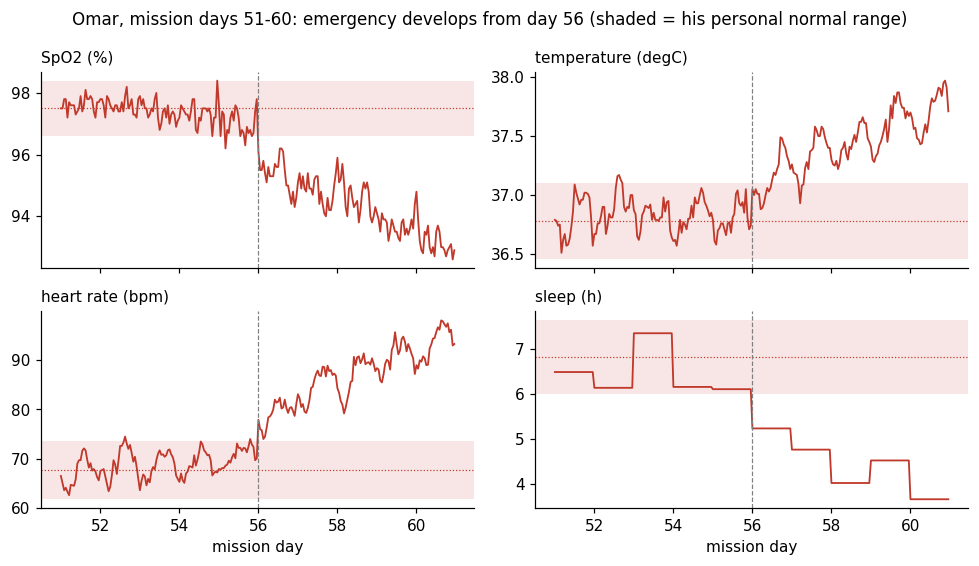

In [13]:
metrics = [("spo2", "SpO2 (%)"), ("temp", "temperature (degC)"), ("hr", "heart rate (bpm)"), ("sleep_hours", "sleep (h)")]
fig, axes = plt.subplots(2, 2, figsize=(9, 5.2), sharex=True)
g = f[(f.astronaut_id == "AST-003") & (f.mission_day >= 51)]
t = g["mission_day"] + g["timestamp"].dt.hour / 24     # fractional mission day
for ax, (m, label) in zip(axes.flat, metrics):
    band(ax, "AST-003", m, COL["AST-003"])
    ax.plot(t, g[m], color=COL["AST-003"], lw=1.2)
    ax.axvline(56, color="grey", lw=0.8, ls="--")
    ax.set_title(label, fontsize=10, loc="left")
for ax in axes[1]:
    ax.set_xlabel("mission day")
fig.suptitle("Omar, mission days 51-60: emergency develops from day 56 (shaded = his personal normal range)", fontsize=11)
fig.tight_layout(); fig.savefig(FIG / "fig3_omar_last_days.png"); plt.show()

### Figure 4 - v1.1 fix: the normal range shown in the app
v1.0 used Q1-Q3, which by definition contains only half of a person's normal readings, so a perfectly healthy astronaut looked 'out of range' half the time. v1.1 uses median +/- 2 robust SD.

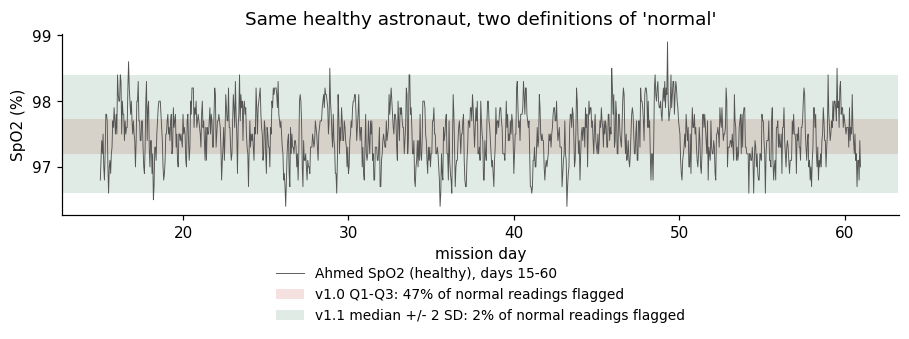

In [14]:
from astroguardian_digital_twin.baseline import compute_feature_baseline
ahmed = f[f.astronaut_id == "AST-001"]; cal = ahmed[ahmed.mission_day <= 14]; after = ahmed[ahmed.mission_day > 14]
cfg_iqr = load_config(); cfg_iqr["baseline"]["default_interval_method"] = "iqr"
old = compute_feature_baseline(cal["spo2"], "spo2", "hourly", cfg_iqr)
new = prof["AST-001"]["baseline_detail"]["spo2"]
fig, ax = plt.subplots(figsize=(8.5, 3.4))
ax.plot(after["mission_day"] + after["timestamp"].dt.hour / 24, after["spo2"], color="#555", lw=0.6, label="Ahmed SpO2 (healthy), days 15-60")
for d, c, lab in ((old, "#c0392b", "v1.0 Q1-Q3"), (new, "#2e7d4f", "v1.1 median +/- 2 SD")):
    out = (~after["spo2"].between(d["low"], d["high"])).mean()
    ax.axhspan(d["low"], d["high"], color=c, alpha=0.15, lw=0, label=f"{lab}: {out:.0%} of normal readings flagged")
ax.set(xlabel="mission day", ylabel="SpO2 (%)", title="Same healthy astronaut, two definitions of 'normal'")
ax.legend(frameon=False, fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.22), ncol=1)
fig.tight_layout(); fig.savefig(FIG / "fig4_normal_range_fix.png"); plt.show()

## 10. Same features at runtime (train/serve parity, v1.1)
The backend receives one reading at a time. `online_features` rebuilds the training columns from the last 7 days of readings, so a model trained on `features_all_astronauts.csv` sees identical inputs live.

In [15]:
from astroguardian_digital_twin import online_features
from astroguardian_digital_twin.data_cleaning import WEARABLE_FIELDS
om = f[f.astronaut_id == "AST-003"].sort_values("timestamp")
row = om[om.mission_day == 58].iloc[12]
hist = om[(om.timestamp > row.timestamp - pd.Timedelta(hours=168)) & (om.timestamp <= row.timestamp)]
history = [{"timestamp": r.timestamp.to_pydatetime(), **{k: getattr(r, k) for k in WEARABLE_FIELDS}} for r in hist.itertuples()]
live = online_features(history, prof["AST-003"])
cols = ["hr_roll24h_mean", "hr_roll168h_mean", "sleep_debt_7d", "stress_score", "hr_pct_dev", "temp_delta_c"]
pd.DataFrame({"training table": [row[c] for c in cols], "runtime (online_features)": [live[c] for c in cols]}, index=cols).round(4)

,training table,runtime (online_features)
hr_roll24h_mean,85.8708,85.8708
hr_roll168h_mean,74.0946,74.0946
sleep_debt_7d,16.2000,16.2000
stress_score,100.0000,100.0000
hr_pct_dev,33.8300,33.8300
temp_delta_c,0.6100,0.6100


## 11. Explanation text (task 11, v1.1)
Top harmful deviations as sentences in English and Arabic. Units follow the metric: points for SpO2, degC for temperature.

In [16]:
from astroguardian_digital_twin import explain_deviation
brief = explain_deviation({"hr": 72, "sleep_hours": 4.9}, prof["AST-001"])   # the brief's example
for r in brief["reasons"]: print(r["text"]["en"], " | ", r["text"]["ar"])
print()
o = explain_deviation({k: float(row[k]) for k in WEARABLE_FIELDS}, prof["AST-003"])
for r in o["reasons"]: print(r["text"]["en"], " | ", r["text"]["ar"])
print("->", o["recommendation"]["en"], " | ", o["recommendation"]["ar"])

Sleep is 29% below your normal (4.9 h vs 6.9 h)  |  النوم أقل من معدلك الطبيعي بنسبة 29% (4.9 ساعة بدل 6.9)
Heart rate is 15% above your normal (72 bpm vs 62.4 bpm)  |  معدل ضربات القلب أعلى من معدلك الطبيعي بنسبة 15% (72 نبضة/دقيقة بدل 62.4)

Blood oxygen (SpO2) is 3 points below your normal (94.5% vs 97.5%)  |  نسبة الأكسجين في الدم أقل من معدلك الطبيعي بـ 3 نقطة (94.5% بدل 97.5%)
Heart rate is 34% above your normal (90.6 bpm vs 67.7 bpm)  |  معدل ضربات القلب أعلى من معدلك الطبيعي بنسبة 34% (90.6 نبضة/دقيقة بدل 67.7)
Breathing rate is 23% above your normal (18.9 breaths/min vs 15.4 breaths/min)  |  معدل التنفس أعلى من معدلك الطبيعي بنسبة 23% (18.9 نفس/دقيقة بدل 15.4)
-> Check oxygen supply and re-measure SpO2 at rest  |  اتأكد من إمداد الأكسجين وقيس النسبة تاني وإنت مرتاح
